# SOC Market Framework -- Reproducing Baldick (2026)

This notebook runs the framework in [`Code/`](..) end to end and shows the results:
Ross Baldick's *state-of-charge based* electricity market design, reproduced on the
three numerical examples from Section 4.7 of the paper (Tables 2-4), plus a look at
the terminal value function `b(.)` that is the framework's central research object.

See [`../README.md`](../README.md) for the model in one paragraph and
[`../ROADMAP.md`](../ROADMAP.md) for the research plan this feeds into.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

# Makes the notebook runnable even without `pip install -e .` having been run first.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from experiments.reproduce_baldick import CASES, run_case
from terminal_value.constant import constant_willingness_to_pay
from terminal_value.piecewise_linear import piecewise_linear_bid

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

## Running the three cases

Each case is the same 6-interval, 4-hour-per-interval system (fixed demand, a thermal
unit at \$50/MWh, a renewable unit with time-varying available capacity) with the ESS
distinguished only by its `s_max` and its constant terminal willingness-to-pay `w`:

| case | `s_max` (MWh) | `w` (\$/MWh) | paper table |
|---|---:|---:|---|
| `base_case` | 800 | 40 | Table 2 |
| `high_willingness_to_pay` | 800 | 55 | Table 3 |
| `increased_max_soc` | 1200 | 40 | Table 4 |

`solve_day_ahead` builds and solves the ISO's welfare-maximizing LP (paper eq. 9) for
each and returns dispatch, SOC, clearing prices, and the resulting ESS surplus.

In [2]:
results = {name: run_case(name) for name in CASES}
list(results)

['base_case', 'high_willingness_to_pay', 'increased_max_soc']

## Base case (Table 2)

Willingness-to-pay \$40/MWh is *below* the thermal offer price (\$50/MWh), so the ESS
draws its SOC all the way back down to the reference `s̄_T = 0` by the end of the
horizon -- there's no benefit to holding energy back at that price.

In [3]:
r = results["base_case"]
display(r.to_frame())
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,0.000,175.000,0.000,100.000,50.000
6,0.000,75.000,25.000,0.000,0.000,50.000


objective (net system cost, $): 19,448.89
terminal value b(.) ($):        0.00
ESS surplus ($):                38,311.11


## High willingness-to-pay (Table 3)

Willingness-to-pay rises to \$55/MWh, *above* the thermal offer price. Thermal
generation increases to cover demand directly, and the ESS instead keeps 500 MWh in
reserve at the end of the horizon to capture that higher off-horizon value.

In [4]:
r = results["high_willingness_to_pay"]
display(r.to_frame())
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,100.000,75.000,0.000,500.000,56.000
6,0.000,100.000,0.000,0.000,500.000,56.000


objective (net system cost, $): 16,448.89
terminal value b(.) ($):        27,500.00
ESS surplus ($):                43,111.11


## Increased max SOC (Table 4)

Same \$40/MWh willingness-to-pay as the base case, but `s_max` raised to 1200 MWh. The
extra headroom lets the ESS absorb more otherwise-curtailed renewable energy in
interval 4 and displace thermal generation entirely after interval 2.

In [5]:
r = results["increased_max_soc"]
display(r.to_frame())
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,433.333,0.000,0.000,133.333,"1,200.000",0.000
5,25.000,0.000,175.000,0.000,500.000,41.000
6,0.000,0.000,100.000,0.000,100.000,41.000


objective (net system cost, $): 1,193.33
terminal value b(.) ($):        4,000.00
ESS surplus ($):                46,666.67


## Dispatch vs. demand, by case

Renewable, thermal, and ESS discharge stacked against demand; ESS charging is shown
as a negative load. Watch the ESS absorb curtailed renewable energy in intervals 1, 3
and 4 and discharge it back in intervals 2, 5 and 6.

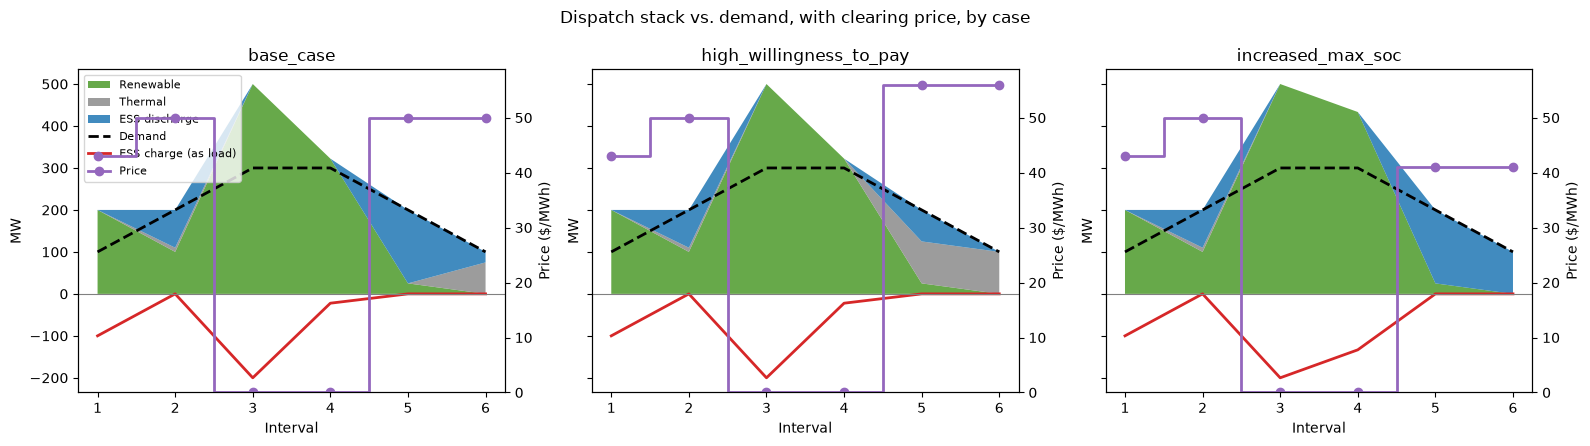

In [6]:
def plot_dispatch(name, result, ax):
    T = len(result.price)
    hours = range(1, T + 1)
    demand = [CASES[name][0].demand[t] for t in range(T)]
    discharge = result.discharge.sum(axis=0)
    charge = result.charge.sum(axis=0)

    ax.stackplot(
        hours,
        result.renewable.sum(axis=0),
        result.thermal.sum(axis=0),
        discharge,
        labels=["Renewable", "Thermal", "ESS discharge"],
        colors=["#4C9A2A", "#8B8B8B", "#1F77B4"],
        alpha=0.85,
    )
    ax.plot(hours, demand, color="black", linewidth=2, linestyle="--", label="Demand")
    ax.plot(hours, -charge, color="#D62728", linewidth=2, label="ESS charge (as load)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Interval")
    ax.set_ylabel("MW")

    ax_price = ax.twinx()
    ax_price.step(hours, result.price, where="mid", color="#9467BD", linewidth=2, marker="o", label="Price")
    ax_price.set_ylabel("Price ($/MWh)")
    return ax_price


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
price_axes = [plot_dispatch(name, results[name], ax) for ax, name in zip(axes, CASES)]

# Same price scale on every panel so the three cases stay visually comparable.
price_max = max(ax.get_ylim()[1] for ax in price_axes)
for ax in price_axes:
    ax.set_ylim(0, price_max)

handles, labels = axes[0].get_legend_handles_labels()
price_handles, price_labels = price_axes[0].get_legend_handles_labels()
axes[0].legend(handles + price_handles, labels + price_labels, loc="upper left", fontsize=8)
fig.suptitle("Dispatch stack vs. demand, with clearing price, by case")
fig.tight_layout()
plt.show()

## SOC trajectories and clearing prices, compared across cases

The SOC lines make the effect of `s_max` and `w` directly visible: all three cases
charge identically in intervals 1-2, but diverge from interval 3 onward as the higher
cap (green) or higher terminal value (orange) change what's worth doing with the
stored energy.

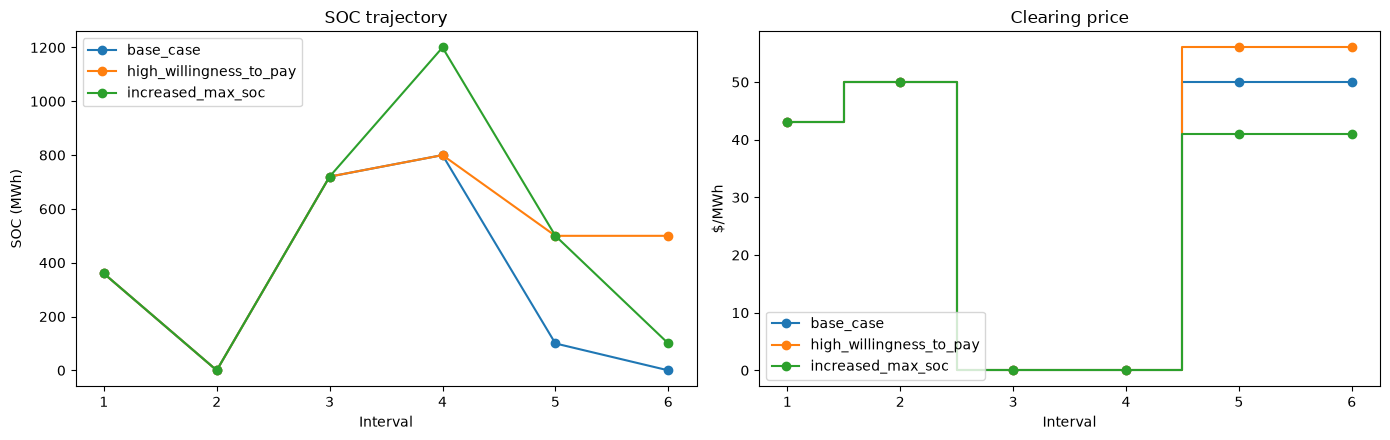

In [7]:
fig, (ax_soc, ax_price) = plt.subplots(1, 2, figsize=(14, 4.5))

for name, r in results.items():
    hours = range(1, len(r.price) + 1)
    ax_soc.plot(hours, r.soc.sum(axis=0), marker="o", label=name)
    ax_price.step(hours, r.price, where="mid", marker="o", label=name)

ax_soc.set_title("SOC trajectory")
ax_soc.set_xlabel("Interval")
ax_soc.set_ylabel("SOC (MWh)")
ax_soc.legend()

ax_price.set_title("Clearing price")
ax_price.set_xlabel("Interval")
ax_price.set_ylabel("$/MWh")
ax_price.legend()

fig.tight_layout()
plt.show()

Interval 1's price sits at \$43.1/MWh in every case -- the upper edge of a
*range* of valid clearing prices there, not a uniquely determined value (the paper
notes this itself; see `ROADMAP.md` for the fuller finding that parts of the *primal*
dispatch are non-unique too, in intervals 3-4 and, in the base case, 5-6).

## Summary metrics across cases

In [8]:
summary = pd.DataFrame(
    {
        name: {
            "objective ($)": r.objective,
            "terminal value b(.) ($)": r.terminal_value.sum(),
            "ESS surplus ($)": r.ess_surplus.sum(),
            "terminal SOC (MWh)": r.terminal_soc.sum(),
        }
        for name, r in results.items()
    }
).T
summary

,objective ($),terminal value b(.) ($),ESS surplus ($),terminal SOC (MWh)
base_case,"19,448.889",0.000,"38,311.111",0.000
high_willingness_to_pay,"16,448.889","27,500.000","43,111.111",500.000
increased_max_soc,"1,193.333","4,000.000","46,666.667",100.000


## The terminal value function `b(.)`

`b(delta)` is the ESS's only private input to the market -- its bid benefit for ending
the horizon `delta` MWh away from the no-participation reference `s̄_T`. The paper's own
examples use a flat marginal willingness-to-pay `w`, giving a straight-line `b`. The
framework's `piecewise_linear_bid` supports any concave shape, which is the building
block for ROADMAP.md's top research direction: comparing perfect-foresight, forecast,
learned, and misspecified terminal value functions under the same market mechanism.

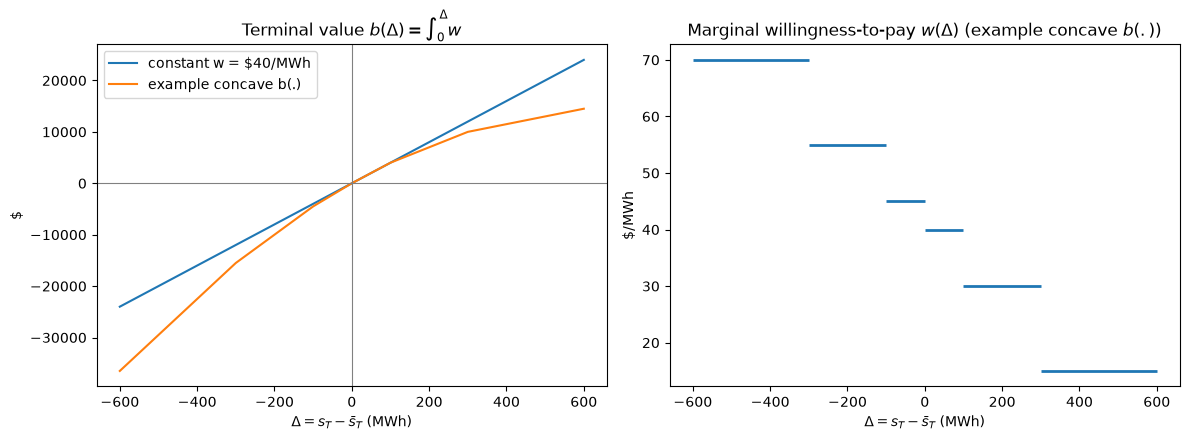

In [9]:
constant_b = constant_willingness_to_pay(w=40.0, cap=1000.0)

# An illustrative concave, two-sided b(.): marginal value falls off as the deviation
# grows in either direction, the kind of shape a learned/forecast value function might
# take -- in contrast to the flat w used in the paper's own worked examples.
example_b = piecewise_linear_bid(
    breakpoints=[-600, -300, -100, 0, 100, 300, 600],
    marginal_values=[70, 55, 45, 40, 30, 15],
)

deviations = range(-600, 601, 20)
fig, (ax_b, ax_w) = plt.subplots(1, 2, figsize=(12, 4.5))

for label, b in [("constant w = $40/MWh", constant_b), ("example concave b(.)", example_b)]:
    ax_b.plot(deviations, [b.value(d) for d in deviations], label=label)
ax_b.axhline(0, color="grey", linewidth=0.8)
ax_b.axvline(0, color="grey", linewidth=0.8)
ax_b.set_title(r"Terminal value $b(\Delta) = \int_0^\Delta w$")
ax_b.set_xlabel(r"$\Delta = s_T - \bar{s}_T$ (MWh)")
ax_b.set_ylabel("$")
ax_b.legend()

bp, mv = example_b.breakpoints, example_b.marginal_values
for k in range(len(mv)):
    ax_w.hlines(mv[k], bp[k], bp[k + 1], color="#1F77B4", linewidth=2)
ax_w.set_title(r"Marginal willingness-to-pay $w(\Delta)$ (example concave $b(.)$)")
ax_w.set_xlabel(r"$\Delta = s_T - \bar{s}_T$ (MWh)")
ax_w.set_ylabel("$/MWh")

fig.tight_layout()
plt.show()

## Next steps

This notebook exercises stage 1 of `ROADMAP.md` ("exact reproduction"). Stages 2-5 --
generalizing beyond the single-thermal/single-renewable/single-storage stylized system,
a conventional interval-bidding benchmark, uncertainty in `b(.)`, and controlled
experiments -- are not yet built. See `ROADMAP.md` for the full plan and the ranked
research directions.